# 붓꽃 품종 분류 실습 (딥러닝 + 원핫인코딩)

ex_0914 붓꽃 실습을 Keras 신경망으로 다시 해 보는 노트북입니다. 와인 노트북과 같은 단계 구성입니다.

## 이 문제는 어떤 유형인가

**다중 분류(multi-class classification)** 입니다. 꽃받침(sepal)과 꽃잎(petal)의 길이와 너비 4개로 품종 3개(setosa, versicolor, virginica) 중 하나를 맞힙니다.

| 구분 | 이진 분류 (당뇨) | 다중 분류 (와인, 붓꽃) |
| --- | --- | --- |
| 정답 형태 | 0 / 1 그대로 | 원핫: [1,0,0], [0,1,0], [0,0,1] |
| 출력층 | `Dense(1, activation='sigmoid')` | `Dense(3, activation='softmax')` |
| 손실함수 | `binary_crossentropy` | `categorical_crossentropy` |
| 예측 읽는 법 | 확률 0.5 이상이면 1 | 확률이 가장 큰 칸 (argmax) |

## 와인 실습과 다른 점

1. **정답이 문자열입니다.** 품종 이름을 먼저 0, 1, 2로 바꾼 뒤 원핫인코딩하고, 예측 결과는 다시 품종 이름으로 되돌립니다.
2. **입력 4개가 모두 cm 단위입니다.** 범위 차이가 작아서 표준화의 효과도 와인보다 작습니다.
3. **기존 모델이 이미 테스트 30개를 모두 맞혔습니다.** 그래서 마지막에 교차검증으로 한 번 더 비교합니다.

위에서부터 차례로 실행하세요. 코랩의 딥러닝은 실행할 때마다 결과가 조금 달라질 수 있습니다.

In [1]:
# [0단계] 코랩 준비: 구글 드라이브 연결과 라이브러리 불러오기
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"     # 텐서플로의 안내 메시지를 줄입니다

DRIVE_PATH = "/content/drive/MyDrive/Colab Notebooks/iris.csv"   # 원래 실습에서 쓰던 경로

try:
    from google.colab import drive
    drive.mount('/content/drive')    # 처음 실행하면 구글 계정 연결 창이 뜹니다
except ImportError:
    pass                             # 코랩이 아니면 건너뜁니다

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical

tf.get_logger().setLevel("ERROR")            # 학습과 무관한 경고 문구를 숨깁니다
print("TensorFlow 버전:", tf.__version__)

TensorFlow 버전: 2.21.0


## [1단계] 데이터 불러오기
드라이브 경로에 `iris.csv`가 없으면 현재 폴더에서 찾고, 그래도 없으면 scikit-learn에 들어 있는 붓꽃 데이터(150개, 품종 3개)를 같은 column 이름으로 불러옵니다.

In [2]:
# [1단계] 데이터 불러오기
candidates = [DRIVE_PATH, "iris.csv"]
CSV_PATH = next((p for p in candidates if os.path.exists(p)), None)

if CSV_PATH:
    df = pd.read_csv(CSV_PATH)
    print("읽은 파일:", CSV_PATH)
else:
    from sklearn.datasets import load_iris
    iris = load_iris(as_frame=True)
    df = iris.data.set_axis(["sepal_length_cm", "sepal_width_cm",
                             "petal_length_cm", "petal_width_cm"], axis=1)
    df["species"] = [iris.target_names[i] for i in iris.target]
    print("iris.csv가 없어 scikit-learn의 붓꽃 데이터를 불러왔습니다.")

# 독립 변수(X)와 타겟 변수(y) 분리
X = df.drop("species", axis=1)
y = df["species"]

print("데이터 형태 (행, 열):", df.shape)
print("품종별 개수:")
display(y.value_counts().to_frame("개수"))
print("상위 5개 데이터 미리보기:")
display(df.head())

읽은 파일: iris.csv
데이터 형태 (행, 열): (150, 5)
품종별 개수:


,개수
species,
setosa,50
versicolor,50
virginica,50


상위 5개 데이터 미리보기:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## [1-1단계] 정답 원핫인코딩
신경망의 출력층은 품종마다 칸이 하나씩, 모두 3칸입니다. 정답도 같은 모양이어야 하므로 품종을 원핫으로 바꿉니다.

**주의:** `to_categorical`은 0, 1, 2 같은 **숫자 번호**만 받습니다. 'setosa' 같은 문자열을 그대로 넣으면 오류가 납니다. 그래서 두 단계로 바꿉니다.

1. `LabelEncoder`로 품종 이름을 번호로 바꿉니다. 이름의 알파벳 순서대로 setosa=0, versicolor=1, virginica=2가 됩니다.
2. 그 번호를 `to_categorical`로 원핫합니다.

In [3]:
# [1-1단계] 정답 원핫인코딩
from sklearn.preprocessing import LabelEncoder

# 잘못된 예: 문자열을 그대로 넣으면 오류가 납니다
try:
    to_categorical(y)
except ValueError as e:
    print("문자열을 그대로 넣었을 때 오류:", e)

# 올바른 예 1단계: 품종 이름 -> 번호
encoder = LabelEncoder()
y_index = encoder.fit_transform(y)
print("\n품종 이름과 번호:", {name: i for i, name in enumerate(encoder.classes_.tolist())})

# 올바른 예 2단계: 번호 -> 원핫
Y = to_categorical(y_index, num_classes=3)
print("원핫 후 모양:", Y.shape)

# 품종마다 한 개씩 확인합니다
sample = [0, 50, 100]                            # setosa, versicolor, virginica의 첫 번째 데이터
display(pd.DataFrame(Y[sample].astype(int),
                     index=[f"{i}번 행 ({y[i]})" for i in sample],
                     columns=[f"{name} 칸" for name in encoder.classes_.tolist()]))

문자열을 그대로 넣었을 때 오류: invalid literal for int() with base 10: 'setosa'

품종 이름과 번호: {'setosa': 0, 'versicolor': 1, 'virginica': 2}
원핫 후 모양: (150, 3)


,setosa 칸,versicolor 칸,virginica 칸
0번 행 (setosa),1,0,0
50번 행 (versicolor),0,1,0
100번 행 (virginica),0,0,1


같은 원핫을 pandas의 `get_dummies`로도 만들 수 있습니다. column 이름에 품종이 붙어서 읽기 쉽고, 결과는 `to_categorical`과 똑같습니다.

In [4]:
# 참고: pandas get_dummies로 만든 원핫과 비교
Y_dummies = pd.get_dummies(y, dtype=int)
display(Y_dummies.iloc[sample])
print("to_categorical 결과와 같은가:", np.array_equal(Y, Y_dummies.values))

,setosa,versicolor,virginica
0,1,0,0
50,0,1,0
100,0,0,1


to_categorical 결과와 같은가: True


## [2단계] 데이터셋 분할 (학습용 / 테스트용)
기존 실습과 비교할 수 있도록 `test_size=0.2`, `random_state=42`를 그대로 씁니다. 입력(X), 원핫 정답(Y), 품종 이름(y)을 한 번에 나누면 세 가지가 같은 행으로 나뉩니다.

In [5]:
# [2단계] 데이터셋 분할 (학습용 / 테스트용)
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test, y_train, y_test = train_test_split(
    X, Y, y, test_size=0.2, random_state=42)

print(f"학습용 데이터 크기: X_train {X_train.shape}, Y_train {Y_train.shape}")
print(f"테스트용 데이터 크기: X_test {X_test.shape}, Y_test {Y_test.shape}")
print("테스트용 품종별 개수:")
display(y_test.value_counts().sort_index().to_frame("개수"))

학습용 데이터 크기: X_train (120, 4), Y_train (120, 3)
테스트용 데이터 크기: X_test (30, 4), Y_test (30, 3)
테스트용 품종별 개수:


,개수
species,
setosa,10
versicolor,9
virginica,11


## [2-1단계] 입력 표준화 (StandardScaler)
붓꽃의 입력 4개는 모두 cm 단위이고 범위가 0.1에서 7.9 사이라서 와인(Proline 최대 1,680)보다 차이가 훨씬 작습니다. 그래도 신경망은 입력이 평균 0, 표준편차 1 근처일 때 안정적으로 학습하므로 표준화합니다.

표준화 기준은 **학습용 데이터로만** 정하고, 테스트 데이터는 그 기준으로 변환만 합니다.

In [6]:
# [2-1단계] 입력 표준화
from sklearn.preprocessing import StandardScaler

print("표준화 전 범위:")
display(X_train.agg(["min", "max"]).round(2))

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)     # 학습용: 기준을 정하고 변환
X_test_s = scaler.transform(X_test)           # 테스트용: 같은 기준으로 변환만

print("표준화 후 학습용 데이터의 평균과 표준편차:")
display(pd.DataFrame(X_train_s, columns=X.columns).agg(["mean", "std"]).round(2))

표준화 전 범위:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
min,4.3,2.0,1.0,0.1
max,7.7,4.4,6.7,2.5


표준화 후 학습용 데이터의 평균과 표준편차:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
mean,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0


## [3단계] 모델 객체 생성
입력 4개 → 은닉층 16개 → 은닉층 8개 → 출력 3개인 신경망입니다. 출력층의 softmax는 3칸의 값을 더해서 1이 되는 확률로 바꿉니다.

In [7]:
# [3단계] 모델 객체 생성
keras.utils.set_random_seed(42)       # 결과 재현을 위해 시작값을 고정합니다

model = keras.Sequential([
    keras.Input(shape=(4,)),                   # 입력: 꽃받침, 꽃잎의 길이와 너비 4개
    layers.Dense(16, activation="relu"),       # 은닉층 1
    layers.Dense(8, activation="relu"),        # 은닉층 2
    layers.Dense(3, activation="softmax"),     # 출력층: 품종 3개의 확률
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

파라미터 수는 (입력 수 × 노드 수 + 노드 수)입니다. 4×16+16 = 80, 16×8+8 = 136, 8×3+3 = 27이라 모두 243개입니다. 입력이 13개였던 와인(387개)보다 첫 층이 작습니다.

## [3-1단계] 모델 컴파일
원핫 정답과 softmax 출력을 비교하는 손실함수는 `categorical_crossentropy`입니다.

In [8]:
# [3-1단계] 모델 컴파일
model.compile(optimizer="adam",
              loss="categorical_crossentropy",   # 원핫 정답 + softmax 출력에 쓰는 손실함수
              metrics=["accuracy"])

## [4단계] 모델 학습
학습용 데이터 120개 중 20%(24개)는 `validation_split`으로 떼어 두고, 학습 중간에 처음 보는 데이터에서도 잘 맞히는지 확인합니다.

In [9]:
# [4단계] 모델 학습
history = model.fit(X_train_s, Y_train,
                    epochs=100,              # 학습 데이터 전체를 100번 반복
                    batch_size=16,           # 16개씩 묶어서 가중치를 갱신
                    validation_split=0.2,    # 학습용의 20%는 검증용으로 사용
                    verbose=0)               # 진행 표시를 끕니다. 1로 바꾸면 매 반복이 보입니다

last = {k: round(v[-1], 3) for k, v in history.history.items()}
print("딥러닝 모델 학습이 완료되었습니다.")
print("마지막 반복의 결과:", last)

딥러닝 모델 학습이 완료되었습니다.
마지막 반복의 결과: {'accuracy': 0.958, 'loss': 0.188, 'val_accuracy': 0.958, 'val_loss': 0.183}


## [4-1단계] 학습 곡선 보기
학습(train)과 검증(validation)의 손실이 함께 내려가면 잘 학습된 것입니다. 학습 손실은 계속 내려가는데 검증 손실만 다시 올라가면 학습 데이터에 지나치게 맞춘 과대적합입니다.

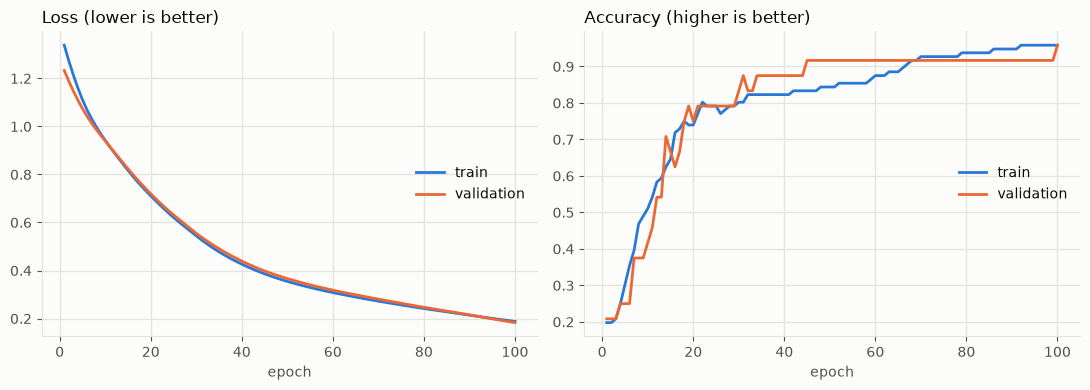

In [10]:
# [4-1단계] 학습 곡선 보기
import matplotlib.pyplot as plt

TRAIN_COLOR, VAL_COLOR = "#2a78d6", "#eb6834"         # 학습 = 파랑, 검증 = 주황
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

epochs = np.arange(1, len(history.history["loss"]) + 1)
panels = [("loss", "Loss (lower is better)"), ("accuracy", "Accuracy (higher is better)")]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), facecolor=SURFACE)
for ax, (key, title) in zip(axes, panels):
    train, val = history.history[key], history.history["val_" + key]
    ax.set_facecolor(SURFACE)
    ax.plot(epochs, train, color=TRAIN_COLOR, linewidth=2, label="train")
    ax.plot(epochs, val, color=VAL_COLOR, linewidth=2, label="validation")
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    ax.set_xlabel("epoch", color=MUTED)
    ax.grid(True, color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED)
    ax.legend(frameon=False, labelcolor=INK, loc="center right")

plt.tight_layout()
plt.show()

## [5단계] 예측 및 성능 평가
`predict`는 품종 3개의 확률을 돌려줍니다. 가장 큰 확률의 칸 번호(argmax)를 고른 뒤, 1-1단계의 `encoder`로 품종 이름으로 되돌립니다.

In [11]:
# [5단계] 예측 및 성능 평가
from sklearn.metrics import classification_report, confusion_matrix

probs = model.predict(X_test_s, verbose=0)                  # 테스트 데이터마다 품종 3개의 확률
pred_dl = encoder.inverse_transform(probs.argmax(axis=1))   # 칸 번호(0, 1, 2) -> 품종 이름

print("예측 확률 미리보기 (상위 5개):")
preview = pd.DataFrame(probs[:5].round(3), columns=[f"{name} 확률" for name in encoder.classes_.tolist()])
preview["예측 품종"] = pred_dl[:5]
preview["실제 품종"] = y_test.values[:5]
display(preview)

# 실제 정답(y_test)과 예측 결과(pred_dl)를 비교하여 성능 리포트 출력
print("\n[딥러닝 분류 성능 평가 리포트]")
print(classification_report(y_test, pred_dl))

names = encoder.classes_.tolist()
print("혼동행렬 (행: 실제 품종, 열: 예측 품종)")
display(pd.DataFrame(confusion_matrix(y_test, pred_dl, labels=names),
                     index=[f"실제 {n}" for n in names], columns=[f"예측 {n}" for n in names]))

예측 확률 미리보기 (상위 5개):


,setosa 확률,versicolor 확률,virginica 확률,예측 품종,실제 품종
0,0.006,0.776,0.218,versicolor,versicolor
1,0.978,0.018,0.004,setosa,setosa
2,0.000,0.015,0.985,virginica,virginica
3,0.008,0.605,0.387,versicolor,versicolor
4,0.001,0.637,0.362,versicolor,versicolor



[딥러닝 분류 성능 평가 리포트]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

혼동행렬 (행: 실제 품종, 열: 예측 품종)


,예측 setosa,예측 versicolor,예측 virginica
실제 setosa,10,0,0
실제 versicolor,0,9,0
실제 virginica,0,0,11


## [6단계] 기존 실습 모델과 비교
같은 분할로 ex_0914의 모델과 비교합니다. 의사결정나무는 원래 `random_state`가 없어 실행할 때마다 결과가 달라졌으므로 42로 고정했습니다. 같은 신경망을 표준화 없이 학습한 결과도 함께 넣었습니다.

In [12]:
# [6단계] 기존 실습 모델과 비교
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

def build_model():
    m = keras.Sequential([keras.Input(shape=(4,)),
                          layers.Dense(16, activation="relu"),
                          layers.Dense(8, activation="relu"),
                          layers.Dense(3, activation="softmax")])
    m.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return m

def make_sklearn_models():
    return {
        "의사결정나무 (ex_0914)": DecisionTreeClassifier(random_state=42),
        "KNN (ex_0914)": KNeighborsClassifier(),
        "로지스틱 회귀 (ex_0914)": LogisticRegression(max_iter=200, random_state=42),
        "랜덤포레스트 (ex_0914)": RandomForestClassifier(random_state=42),
    }

# 같은 신경망을 표준화 없이 학습
keras.utils.set_random_seed(42)
raw_model = build_model()
raw_model.fit(X_train.values, Y_train, epochs=100, batch_size=16, validation_split=0.2, verbose=0)
pred_raw_dl = encoder.inverse_transform(raw_model.predict(X_test.values, verbose=0).argmax(axis=1))

rows = [(name, "원본", accuracy_score(y_test, m.fit(X_train, y_train).predict(X_test)))
        for name, m in make_sklearn_models().items()]
rows += [("딥러닝", "원본 (표준화 없음)", accuracy_score(y_test, pred_raw_dl)),
         ("딥러닝 (이 노트북)", "표준화", accuracy_score(y_test, pred_dl))]
display(pd.DataFrame(rows, columns=["모델", "입력", "테스트 정확도"]).round(3))

,모델,입력,테스트 정확도
0,의사결정나무 (ex_0914),원본,1.000
1,KNN (ex_0914),원본,1.000
2,로지스틱 회귀 (ex_0914),원본,1.000
3,랜덤포레스트 (ex_0914),원본,1.000
4,딥러닝,원본 (표준화 없음),0.967
5,딥러닝 (이 노트북),표준화,1.000


## [7단계] 교차검증으로 다시 비교
테스트 데이터가 30개뿐이고 대부분의 모델이 전부 맞혀서, 이 분할로는 차이가 보이지 않습니다. 데이터를 5번 다르게 나눠 평균을 내는 교차검증으로 다시 비교합니다. 신경망은 나눌 때마다 표준화 기준을 새로 정하고 새로 학습합니다. 신경망 5개를 학습하므로 30초쯤 걸립니다.

In [13]:
# [7단계] 5-fold 교차검증 비교
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = {name: [] for name in list(make_sklearn_models()) + ["딥러닝 (표준화)"]}

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), start=1):
    Xa, Xb = X.iloc[train_idx], X.iloc[test_idx]
    ya, yb = y.iloc[train_idx], y.iloc[test_idx]

    for name, m in make_sklearn_models().items():
        scores[name].append(accuracy_score(yb, m.fit(Xa, ya).predict(Xb)))

    fold_scaler = StandardScaler().fit(Xa)                       # 이번 학습용으로만 기준을 정합니다
    keras.utils.set_random_seed(42)
    nn = build_model()
    nn.fit(fold_scaler.transform(Xa), to_categorical(encoder.transform(ya), num_classes=3),
           epochs=100, batch_size=16, verbose=0)
    pred = encoder.inverse_transform(nn.predict(fold_scaler.transform(Xb), verbose=0).argmax(axis=1))
    scores["딥러닝 (표준화)"].append(accuracy_score(yb, pred))
    print(f"{fold}번째 나누기 완료")

cv_table = pd.DataFrame({name: [np.mean(s), np.std(s)] for name, s in scores.items()},
                        index=["평균 정확도", "표준편차"]).T
display(cv_table.round(3))

1번째 나누기 완료


2번째 나누기 완료


3번째 나누기 완료


4번째 나누기 완료


5번째 나누기 완료


,평균 정확도,표준편차
의사결정나무 (ex_0914),0.953,0.034
KNN (ex_0914),0.967,0.030
로지스틱 회귀 (ex_0914),0.967,0.030
랜덤포레스트 (ex_0914),0.947,0.027
딥러닝 (표준화),0.960,0.053


## [8단계] 원핫 없이 하는 방법도 알아 두기
Keras에는 정답을 원핫으로 바꾸지 않고 번호(0, 1, 2) 그대로 쓰는 손실함수 `sparse_categorical_crossentropy`도 있습니다. 문자열은 여전히 `LabelEncoder`로 번호로 바꿔야 합니다.

| 정답 형태 | 손실함수 |
| --- | --- |
| 원핫 [0, 1, 0] | `categorical_crossentropy` |
| 번호 1 (0부터 시작) | `sparse_categorical_crossentropy` |

In [14]:
# [8단계] 원핫 없이 번호 그대로 학습하기
keras.utils.set_random_seed(42)
sparse_model = keras.Sequential([keras.Input(shape=(4,)),
                                 layers.Dense(16, activation="relu"),
                                 layers.Dense(8, activation="relu"),
                                 layers.Dense(3, activation="softmax")])
sparse_model.compile(optimizer="adam",
                     loss="sparse_categorical_crossentropy",   # 정답이 번호(0, 1, 2)일 때
                     metrics=["accuracy"])

y_train_index = encoder.transform(y_train)                     # 품종 이름 -> 번호 (원핫은 하지 않음)
sparse_model.fit(X_train_s, y_train_index, epochs=100, batch_size=16,
                 validation_split=0.2, verbose=0)

pred_sparse = encoder.inverse_transform(sparse_model.predict(X_test_s, verbose=0).argmax(axis=1))
print("정답 모양:", y_train_index[:5], " (원핫이 아니라 번호)")
print("테스트 정확도:", round(accuracy_score(y_test, pred_sparse), 3))

정답 모양: [0 0 1 0 0]  (원핫이 아니라 번호)
테스트 정확도: 1.0


## 정리

- 붓꽃 데이터는 품종 3개 중 하나를 맞히는 **다중 분류**입니다. 딥러닝 구성은 와인과 같습니다: **정답 원핫인코딩 + `Dense(3, softmax)` + `categorical_crossentropy`**.
- 정답이 **문자열**이면 `LabelEncoder`로 번호를 만든 뒤 원핫합니다. 예측한 번호는 같은 인코더의 `inverse_transform`으로 품종 이름으로 되돌립니다.
- `pd.get_dummies`로 만든 원핫도 결과는 같습니다. 다만 예측을 품종 이름으로 되돌릴 때는 번호와 이름의 짝이 필요하므로 `LabelEncoder`가 편합니다.
- 붓꽃처럼 작고 쉬운 데이터에서는 신경망이 기존 모델보다 낫다고 하기 어렵습니다. 교차검증 결과(7단계)를 보면 모델 사이의 차이는 대부분 1~2개를 더 맞히고 덜 맞히는 정도입니다.
- 테스트 정확도 1.000은 30개 중 30개를 맞혔다는 뜻입니다. 하나만 틀려도 0.967이 되므로 교차검증과 함께 보는 습관이 필요합니다.

## 더 해볼 것

1. 은닉층을 하나로 줄이거나 노드 수를 4개로 줄여도 잘 맞히는지 확인하기
2. 꽃잎 길이와 너비(petal) 두 column만으로 학습해 보고 정확도가 얼마나 유지되는지 보기
3. 4-1단계 학습 곡선을 보면 100번째 반복에서도 손실이 아직 내려가는 중입니다. `epochs`를 200으로 늘려 손실과 정확도가 어떻게 변하는지 확인하기
4. 와인 노트북과 학습 곡선을 나란히 비교하기